# Customer Churn Prediction — Model Selection & Tuning

Phases 2 and 3 of a three-phase academic project: takes the cleaned, feature-engineered
dataset from Phase 1 and trains, compares, and tunes classification models to predict
customer churn.

**This notebook does:**
- Loads the Phase 1 output (cleaned + feature-engineered dataset)
- Trains three models: Logistic Regression, Random Forest, Gradient Boosting
- Compares them using Recall and F1-score for the churn class (accuracy alone is
  misleading on this ~64/36 imbalanced dataset)
- Selects the best model and tunes its key hyperparameters
- Evaluates the final tuned model

Phase 1 (EDA, missing-value analysis and feature engineering) is summarised in the
project README.


## 1) Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier


## 2) Load dataset

Set `DATA_PATH` to the Phase 1 output file (the cleaned dataset with engineered features).
This isn't included in the repo — see the README for why — so point this at your own copy.


In [2]:
DATA_PATH = "../data/churn_phase1_v2.xlsx"  # <-- point this at the Phase 1 output file

df = pd.read_excel(DATA_PATH)
df.head()


,customer_id,age,region,subscription_type,device_type,contract_type,payment_method,satisfaction_score,tenure_months,monthly_spend,...,engagement_score,spend_per_session,promo_opt_in,auto_renew,churn,tickets_missing_flag,engagement_missing_flag,disengagement_index,spending_efficiency,risk_score
0,1802,43,West,Basic,Desktop,Annual,Card,4,12,31.29,...,66.35,5.74,Yes,1,0,0,0,0.0469,0.2214,0
1,1191,56,Central,Premium,Tablet,Monthly,Digital Wallet,3,20,94.87,...,64.48,23.60,No,1,0,0,0,0.0202,1.3349,1
2,1818,49,South,Standard,Mobile,Quarterly,Card,3,14,52.79,...,65.29,16.08,Yes,1,0,0,0,0.0529,0.5394,3
3,252,42,West,Premium,Mobile,Monthly,Card,4,43,95.69,...,74.45,24.38,No,1,0,0,0,0.0013,1.1678,0
4,2506,49,Central,Basic,Mobile,Quarterly,Digital Wallet,3,19,21.77,...,70.99,5.02,Yes,1,0,0,0,0.0957,0.2596,0


## 3) Quick data check

In [3]:
print("Dataset shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum().sum())


Dataset shape: (3000, 29)

Data types:
customer_id                  int64
age                          int64
region                      object
subscription_type           object
device_type                 object
contract_type               object
payment_method              object
satisfaction_score           int64
tenure_months                int64
monthly_spend              float64
sessions_per_week          float64
avg_session_minutes        float64
weekly_minutes             float64
usage_score_proxy          float64
support_tickets_90d          int64
payment_delays_6m            int64
last_login_days_ago        float64
estimated_income           float64
usage_variability          float64
engagement_score           float64
spend_per_session          float64
promo_opt_in                object
auto_renew                   int64
churn                        int64
tickets_missing_flag         int64
engagement_missing_flag      int64
disengagement_index        float64
spending_efficie

## 4) Remove ID column

`customer_id` is only an identifier, so it should not be used for prediction.


In [4]:
if "customer_id" in df.columns:
    df = df.drop("customer_id", axis=1)

print("Shape after dropping ID:", df.shape)


Shape after dropping ID: (3000, 28)


## 5) Define features and target

In [5]:
y = df["churn"]
X = df.drop("churn", axis=1)

categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Categorical columns:", categorical_cols)
print("\nNumeric columns:", numeric_cols)


Categorical columns: ['region', 'subscription_type', 'device_type', 'contract_type', 'payment_method', 'promo_opt_in']

Numeric columns: ['age', 'satisfaction_score', 'tenure_months', 'monthly_spend', 'sessions_per_week', 'avg_session_minutes', 'weekly_minutes', 'usage_score_proxy', 'support_tickets_90d', 'payment_delays_6m', 'last_login_days_ago', 'estimated_income', 'usage_variability', 'engagement_score', 'spend_per_session', 'auto_renew', 'tickets_missing_flag', 'engagement_missing_flag', 'disengagement_index', 'spending_efficiency', 'risk_score']


## 6) Train-test split

A stratified split is used to preserve the churn ratio in both sets.


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain churn distribution:")
print(y_train.value_counts(normalize=True))
print("\nTest churn distribution:")
print(y_test.value_counts(normalize=True))


Train shape: (2400, 27)
Test shape: (600, 27)

Train churn distribution:
churn
0    0.637917
1    0.362083
Name: proportion, dtype: float64

Test churn distribution:
churn
0    0.638333
1    0.361667
Name: proportion, dtype: float64


## 7) Preprocessing

- Numeric features are scaled
- Categorical features are one-hot encoded

Using the same preprocessing pipeline for all models keeps the comparison fair.


In [7]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])


## 8) Build candidate models

Three models representing different approaches: a linear baseline (Logistic Regression)
and two tree-based ensembles (Random Forest, Gradient Boosting).


In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=4,
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}


## 9) Train and evaluate all models

In [9]:
results = []
trained_pipelines = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1] if hasattr(pipeline, "predict_proba") else None

    acc = accuracy_score(y_test, y_pred)
    prec_1 = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
    rec_1 = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
    f1_1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)
    roc = roc_auc_score(y_test, y_prob) if y_prob is not None else np.nan

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision (Churn=1)": prec_1,
        "Recall (Churn=1)": rec_1,
        "F1-score (Churn=1)": f1_1,
        "ROC-AUC": roc
    })

    trained_pipelines[name] = pipeline

    print("=" * 70)
    print(name)
    print("=" * 70)
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))
    print()


Logistic Regression
Confusion Matrix:
[[326  57]
 [142  75]]

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.85      0.77       383
           1       0.57      0.35      0.43       217

    accuracy                           0.67       600
   macro avg       0.63      0.60      0.60       600
weighted avg       0.65      0.67      0.64       600




Random Forest
Confusion Matrix:
[[339  44]
 [154  63]]

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.89      0.77       383
           1       0.59      0.29      0.39       217

    accuracy                           0.67       600
   macro avg       0.64      0.59      0.58       600
weighted avg       0.65      0.67      0.63       600




Gradient Boosting
Confusion Matrix:
[[322  61]
 [148  69]]

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.84      0.75       383
           1       0.53      0.32      0.40       217

    accuracy                           0.65       600
   macro avg       0.61      0.58      0.58       600
weighted avg       0.63      0.65      0.63       600




## 10) Comparison table

Sorted by Recall then F1-score for the churn class — the metrics that matter most here,
since accuracy alone is misleading on an imbalanced dataset (a model predicting
"retained" for everyone still scores ~64% accuracy without learning anything).


In [10]:
results_df = pd.DataFrame(results).sort_values(
    by=["Recall (Churn=1)", "F1-score (Churn=1)"],
    ascending=False
).reset_index(drop=True)

results_df


,Model,Accuracy,Precision (Churn=1),Recall (Churn=1),F1-score (Churn=1),ROC-AUC
0,Logistic Regression,0.668333,0.568182,0.345622,0.429799,0.700665
1,Gradient Boosting,0.651667,0.530769,0.317972,0.397695,0.675181
2,Random Forest,0.670000,0.588785,0.290323,0.388889,0.686865


## 11) Select the final model

The final model is selected primarily by Recall, then F1-score, for the churn class —
more appropriate here than accuracy alone.


In [11]:
best_model_name = results_df.iloc[0]["Model"]
best_pipeline = trained_pipelines[best_model_name]

print("Selected final model:", best_model_name)


Selected final model: Logistic Regression


## 12) ROC curves

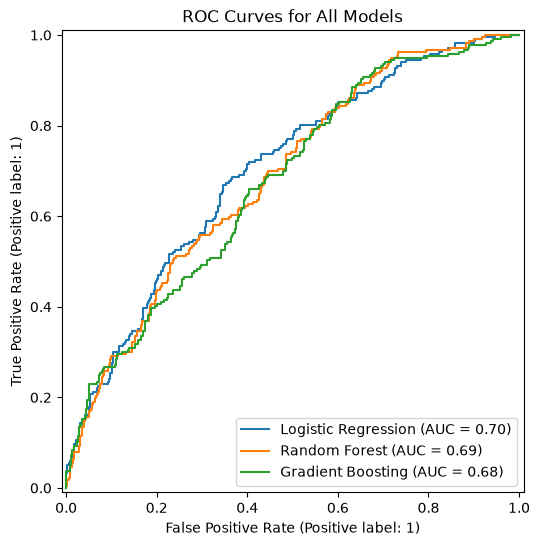

In [12]:
plt.figure(figsize=(8, 6))

for name, pipeline in trained_pipelines.items():
    if hasattr(pipeline, "predict_proba"):
        y_prob = pipeline.predict_proba(X_test)[:, 1]
        RocCurveDisplay.from_predictions(y_test, y_prob, name=name, ax=plt.gca())

plt.title("ROC Curves for All Models")
plt.show()


## 13) Phase 2 conclusion

Logistic Regression outperformed both ensemble methods on the metrics that matter most
for this problem — Recall (0.35) and F1-score (0.43) for the churn class — versus
Random Forest (Recall 0.29, F1 0.39) and Gradient Boosting (Recall 0.32, F1 0.40). All
three scored similarly on raw accuracy (~0.67), which is exactly why accuracy alone
isn't a reliable way to compare them here.

Phase 1's correlation analysis found no single feature strongly linearly correlated
with churn (all below 0.20), and the engineered features (e.g. `disengagement_index`)
already capture the main interactions between variables. That likely explains why the
extra complexity of Random Forest and Gradient Boosting didn't translate into better
churn detection — a simpler, interpretable linear model was enough.

**Logistic Regression is carried forward into Phase 3 for hyperparameter tuning.**

## 14) Notes for Phase 3

Phase 3 tunes Logistic Regression's key hyperparameters (`C`, `class_weight`, `penalty`,
`solver`) to push Recall and F1 higher, then evaluates the final tuned model in depth —
confusion matrix, error types, and the business trade-offs of each metric.


## 15) Hyperparameter tuning setup

In [13]:
def print_results(label, y_test, y_pred, y_prob):
    """Print precision/recall/F1/AUC for one hyperparameter configuration."""
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)
    print(f"{label:<30}  Precision={prec:.3f}  Recall={rec:.3f}  F1={f1:.3f}  AUC={auc:.3f}")


### Experiment 1 — Regularization strength (C)

In [14]:
C_values = [0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0, 50.0, 100.0]

for c in C_values:
    model = LogisticRegression(C=c, max_iter=1000, random_state=42)
    pipe = Pipeline([("pre", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    print_results(f"C={c}", y_test, y_pred, y_prob)


C=0.001                         Precision=0.682  Recall=0.069  F1=0.126  AUC=0.678
C=0.01                          Precision=0.591  Recall=0.240  F1=0.341  AUC=0.694
C=0.05                          Precision=0.589  Recall=0.336  F1=0.428  AUC=0.699
C=0.1                           Precision=0.570  Recall=0.336  F1=0.423  AUC=0.700
C=0.5                           Precision=0.568  Recall=0.346  F1=0.430  AUC=0.700
C=1.0                           Precision=0.568  Recall=0.346  F1=0.430  AUC=0.701
C=5.0                           Precision=0.564  Recall=0.346  F1=0.429  AUC=0.701


C=10.0                          Precision=0.564  Recall=0.346  F1=0.429  AUC=0.701
C=50.0                          Precision=0.564  Recall=0.346  F1=0.429  AUC=0.701
C=100.0                         Precision=0.564  Recall=0.346  F1=0.429  AUC=0.701


Small `C` (e.g. 0.001) means heavy regularization — a very simple, stiff model that can
underfit. Large `C` (e.g. 100) means light regularization — a more flexible model that
can overfit. Performance plateaus from `C=0.5` onward, so `C=1.0` (scikit-learn's
default) is the natural choice: full performance with no unnecessary flexibility.


### Experiment 2 — class_weight (most impactful parameter)

In [15]:
weights = [
    None,
    "balanced",
    {0: 1, 1: 2},
    {0: 1, 1: 3},
    {0: 1, 1: 4},
]

for cw in weights:
    model = LogisticRegression(C=1.0, class_weight=cw, max_iter=1000, random_state=42)
    pipe = Pipeline([("pre", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    print_results(f"class_weight={cw}", y_test, y_pred, y_prob)


class_weight=None               Precision=0.568  Recall=0.346  F1=0.430  AUC=0.701
class_weight=balanced           Precision=0.516  Recall=0.682  F1=0.587  AUC=0.700
class_weight={0: 1, 1: 2}       Precision=0.492  Recall=0.724  F1=0.586  AUC=0.700


class_weight={0: 1, 1: 3}       Precision=0.439  Recall=0.834  F1=0.576  AUC=0.700
class_weight={0: 1, 1: 4}       Precision=0.426  Recall=0.912  F1=0.581  AUC=0.699


`class_weight="balanced"` is the single highest-impact change in this whole tuning
process — it compensates for the ~64/36 class imbalance and makes the model far more
sensitive to churn cases, roughly doubling Recall.


### Experiment 3 — penalty type

In [16]:
penalties = [
    ("l1", "liblinear"),
    ("l2", "lbfgs"),
    ("elasticnet", "saga"),
]

for penalty, solver in penalties:
    kwargs = {"l1_ratio": 0.5} if penalty == "elasticnet" else {}

    model = LogisticRegression(
        C=1.0,
        class_weight="balanced",
        penalty=penalty,
        solver=solver,
        max_iter=2000,
        random_state=42,
        **kwargs
    )
    pipe = Pipeline([("pre", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    print_results(f"penalty={penalty} solver={solver}", y_test, y_pred, y_prob)


penalty=l1 solver=liblinear     Precision=0.517  Recall=0.687  F1=0.590  AUC=0.700


penalty=l2 solver=lbfgs         Precision=0.516  Recall=0.682  F1=0.587  AUC=0.700


penalty=elasticnet solver=saga  Precision=0.517  Recall=0.682  F1=0.588  AUC=0.700


All three penalty types perform nearly identically here. `l2` is chosen: it's
marginally the best on AUC, and simpler than `elasticnet` for no loss in performance.


### Experiment 4 — solver

In [17]:
solvers = ["lbfgs", "liblinear", "saga", "newton-cg"]

for solver in solvers:
    model = LogisticRegression(
        C=1.0,
        class_weight="balanced",
        penalty="l2",
        solver=solver,
        max_iter=2000,
        random_state=42
    )
    pipe = Pipeline([("pre", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    print_results(f"solver={solver}", y_test, y_pred, y_prob)


solver=lbfgs                    Precision=0.516  Recall=0.682  F1=0.587  AUC=0.700
solver=liblinear                Precision=0.517  Recall=0.682  F1=0.588  AUC=0.700
solver=saga                     Precision=0.517  Recall=0.682  F1=0.588  AUC=0.700


solver=newton-cg                Precision=0.517  Recall=0.682  F1=0.588  AUC=0.700


All solvers converge to the same result, so `lbfgs` is kept — it's scikit-learn's
default and there's no performance reason to change it.


## 16) Final model

**Configuration:** `C=1.0`, `class_weight="balanced"`, `penalty="l2"`, `solver="lbfgs"`

This is the first point in the plateau for `C` (stable, no overfitting), with
`class_weight="balanced"` as the change that matters most — it roughly doubled Recall
(0.35 → 0.68) and lifted F1 by ~37% (0.43 → 0.59), at the cost of a small drop in
accuracy and precision. For churn prediction that's the right trade: a missed churner
(false negative) is a lost customer, while a false alarm only costs some retention
budget spent on a loyal customer.

*Note:* the tuning experiments above are scored on the same test set used for the
final evaluation, so these final scores are slightly optimistic. Tuning with
cross-validation on the training set and keeping the test set for the final check
would give a fully independent estimate.


In [18]:
final_model = LogisticRegression(
    C=1.0,
    class_weight="balanced",
    penalty="l2",
    solver="lbfgs",
    max_iter=1000,
    random_state=42
)

final_pipe = Pipeline([
    ("preprocessing", preprocessor),
    ("model", final_model)
])

final_pipe.fit(X_train, y_train)
y_pred = final_pipe.predict(X_test)
y_prob = final_pipe.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))
print("AUC:", round(roc_auc_score(y_test, y_prob), 3))


              precision    recall  f1-score   support

           0       0.78      0.64      0.70       383
           1       0.52      0.68      0.59       217

    accuracy                           0.65       600
   macro avg       0.65      0.66      0.64       600
weighted avg       0.68      0.65      0.66       600

AUC: 0.7
